In [15]:
%%time
#%load_ext autoreload
#%autoreload 2

CPU times: total: 0 ns
Wall time: 8.82 μs


# Imports

In [16]:
%%time
import itertools
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import skeliner as sk
from IPython.display import Markdown, display
from matplotlib.font_manager import FontProperties
from matplotlib.lines import Line2D
from matplotlib.text import Text
from matplotlib.textpath import TextPath
from matplotlib.ticker import MultipleLocator
from matplotlib.transforms import Bbox
from scipy.interpolate import BSpline
from scipy.optimize import least_squares
from shapely.geometry import MultiPoint, Polygon

set_rc_params(notebook_dpi=110)
pd.set_option("display.width", 220)

CPU times: total: 0 ns
Wall time: 4.57 ms


In [17]:
%%time
import itertools
import os
import sys
import warnings
sys.path.append("../utils")

import data_2p_loader as data_loader
import data_io
import rf
from style import set_rc_params

CPU times: total: 0 ns
Wall time: 29.8 μs


In [18]:
KEY_COLS = data_loader.ROI_KEY_COLS  # experimenter, date, exp_num, field, roi_id
CHANNELS = list(rf.CHANNELS)         # ('green', 'uv')
EM_TYPE = "ON sustained alpha"       # EM 'Cell Type' of the sON alpha RGCs (formerly "ON alpha"; the same 5 cells)
EXAMPLE_ROI = ("GCL3", 52)           # the example cell of Fig. 6A-G (nucleus 720575940567697697)

# RF quality and inclusion: identical to rgc_rf_morphology_sOnalpha.ipynb (eyewire2-functional-analysis)
REQUIRE_QFILT = True    # chirp / moving-bar response quality filter
CC_MIN = 0.10           # min. RF model test correlation (joint green + UV model)
R2_MIN = 0.50           # min. DoG fit R² of the channel's spatial RF
EDGE_PX = 2             # DoG center must be >= EDGE_PX pixels inside the stimulus window
ALIGN = True            # established alignment: stimulus shift (RF) + EM affine (skeleton), from rf_alignment.yaml
N_SIGMA = 2.0           # RF center = N_SIGMA ellipse of the DoG center Gaussian
EXCLUDE_CUT_OFF = True  # exclude EM arbors cut off at the volume edge
DENDRITE_NTYPE = 3      # SWC node type of dendrites

CH_COLORS, CH_LABELS = rf.CH_COLORS, rf.CH_LABELS

# Data

In [ ]:
%%time
config = data_io.get_data_config()
skel_dir = config["skel_dir"]
for f in (config["mc_rf_file"], config["em_2p_registration_file"], config["rf_alignment_file"]):
    assert os.path.isfile(os.path.join(config["data_2p_dir"], f)), f"{f} not found in {config['data_2p_dir']}"
assert os.path.isdir(skel_dir), skel_dir

df_rois = data_loader.load_df_rois()
df_morph = data_loader.load_df_rois_morph(df_rois=df_rois)
df_rf = data_loader.load_df_mc_rfs()
reg = data_loader.load_registration()
ALIGNMENT = data_loader.load_rf_alignment() if ALIGN else None

In [19]:
def load_skel(row):
    """Skeleton of the cell's `Latest SegID`, else of its `Proofread SegID` (an older proofreading state); None if
    neither SWC exists."""
    for col in ("Latest SegID", "Proofread SegID"):
        path = os.path.join(skel_dir, f"{row[col]}.swc")
        if pd.notna(row[col]) and os.path.isfile(path):
            return sk.io.load_skeleton_swc(path)
    return None


is_ex = (df_morph.field == EXAMPLE_ROI[0]) & (df_morph.roi_id == EXAMPLE_ROI[1])
df_all = df_morph[(df_morph["Cell Type"] == EM_TYPE) | is_ex].merge(df_rf, on=KEY_COLS, how="left",
                                                                     validate="one_to_one")
df_all["skel"] = [load_skel(row) for _, row in df_all.iterrows()]
df_all["label"] = "F" + df_all.field.str[-1] + " ROI " + df_all.roi_id.astype(str)
df_all["cut_off"] = df_all.Status.astype(str).str.contains("cut off")
df = df_all[df_all["Cell Type"] == EM_TYPE].sort_values(["field", "roi_id"]).reset_index(drop=True)
row52 = df_all[(df_all.field == EXAMPLE_ROI[0]) & (df_all.roi_id == EXAMPLE_ROI[1])].iloc[0]
assert len(df) > 0 and not df.duplicated(KEY_COLS).any()
N_PX = df.mc_rf_green_srf.dropna().iloc[0].shape[0]
equiv_diameter = lambda area: 2 * np.sqrt(area / np.pi)

In [30]:
def rf_channel_usable(row, ch):
    if pd.isna(row[f"mc_rf_{ch}_dog_r2"]):
        return False
    return bool((row.qfilt or not REQUIRE_QFILT) and row.mc_rf_best_cc >= CC_MIN
                and row[f"mc_rf_{ch}_dog_r2"] >= R2_MIN
                and all(EDGE_PX <= row[f"mc_rf_{ch}_dog_{xy}0"] <= N_PX - 1 - EDGE_PX for xy in "xy"))


def place_skeleton(row):
    """Skeleton in the retinal frame (µm, x = nasal, y = dorsal), soma at the origin."""
    skel = rf.place_skel(row.skel, reg, row.field, alignment=ALIGNMENT)
    assert np.allclose(skel.soma.center[:2], 0)
    return skel


def dendritic_hull(skel):
    xy = skel.nodes[skel.ntype == DENDRITE_NTYPE, :2]
    hull = MultiPoint(xy).convex_hull if len(xy) >= 3 else None
    return hull if hull is not None and hull.geom_type == "Polygon" and hull.area > 0 else None


def rf_center(row, ch):
    """2σ DoG center ellipse (Shapely polygon), its analytic area and its center (µm, soma-centered)."""
    ellipse = Polygon(np.column_stack(rf.dog_ellipse(row, ch, n_sigma=N_SIGMA, n=400, alignment=ALIGNMENT)))
    area = np.pi * N_SIGMA ** 2 * row[f"mc_rf_{ch}_dog_sx"] * row[f"mc_rf_{ch}_dog_sy"] * row.mc_rf_pixel_size_um ** 2
    cx, cy = rf._movie_px_to_retina_um(row, row[f"mc_rf_{ch}_dog_x0"], row[f"mc_rf_{ch}_dog_y0"],
                                       row[f"mc_rf_{ch}_srf"].shape, alignment=ALIGNMENT)
    assert abs(ellipse.area / area - 1) < 1e-3, "plotted ellipse does not match the analytic area"
    assert np.hypot(ellipse.centroid.x - cx, ellipse.centroid.y - cy) < 1e-3
    return ellipse, area, (float(cx), float(cy))


# GEOM[label]: skeleton, hull, and per usable channel the RF center ellipse and center (used for the drawings)
GEOM, obs = {}, []
for _, row in pd.concat([df, row52.to_frame().T], ignore_index=True).iterrows():
    skel = place_skeleton(row) if row.skel is not None else None
    hull = dendritic_hull(skel) if skel is not None else None
    g = GEOM[row.label] = dict(skel=skel, hull=hull, ellipse={}, center={}, included=set(),
                               r2={ch: row[f"mc_rf_{ch}_dog_r2"] for ch in CHANNELS})
    for ch in CHANNELS:
        if not rf_channel_usable(row, ch):
            continue
        ellipse, area, (cx, cy) = rf_center(row, ch)
        g["ellipse"][ch], g["center"][ch] = ellipse, (cx, cy)
        if row["Cell Type"] != EM_TYPE:  # the example ROI 52 is only drawn, not part of the statistics
            continue
        if hull is None or hull.intersection(ellipse).area == 0 or (EXCLUDE_CUT_OFF and row.cut_off):
            continue
        g["included"].add(ch)
        obs.append(dict(label=row.label, field=row.field, roi_id=row.roi_id, channel=ch, cc=row.mc_rf_best_cc,
                        dend_area_um2=hull.area, rf_area_um2=area,
                        rf_cov=min(hull.intersection(ellipse).area / ellipse.area, 1.),
                        dx_um=cx - hull.centroid.x, dy_um=cy - hull.centroid.y))
df_obs = pd.DataFrame(obs)
df_obs["dend_diam_um"] = equiv_diameter(df_obs.dend_area_um2)
df_obs["rf_diam_um"] = equiv_diameter(df_obs.rf_area_um2)
df_obs["diam_ratio"] = df_obs.rf_diam_um / df_obs.dend_diam_um
df_obs["offset_um"] = np.hypot(df_obs.dx_um, df_obs.dy_um)

In [31]:
def bspline_basis(n, df, degree=3):
    """B-spline basis of shape (n, df) with uniformly spaced knots on 0, ..., n - 1."""
    inner = np.linspace(0, n - 1, df - degree + 1)
    knots = np.r_[[inner[0]] * degree, inner, [inner[-1]] * degree]
    return BSpline.design_matrix(np.arange(n, dtype=float), knots, degree).toarray()


def unit_gauss(xx, yy, x0, y0, sx, sy, theta):
    a = np.cos(theta) ** 2 / (2 * sx ** 2) + np.sin(theta) ** 2 / (2 * sy ** 2)
    b = -np.sin(2 * theta) / (4 * sx ** 2) + np.sin(2 * theta) / (4 * sy ** 2)
    c = np.sin(theta) ** 2 / (2 * sx ** 2) + np.cos(theta) ** 2 / (2 * sy ** 2)
    return np.exp(-(a * (xx - x0) ** 2 + 2 * b * (xx - x0) * (yy - y0) + c * (yy - y0) ** 2))


def fit_dog_sigmas(srfs, center_prior_sd=4., center_prior_weight=0.05, coupling_weight=0.05,
                   surround_ratio=(2., 10.), sigma_init=(1.5, 4.)):
    """Joint DoG fit to the sRFs (n_channels, ny, nx), with soft priors on the centers (window center and coupling of
    the channels); returns the center sigmas (sx, sy) per channel, in pixels."""
    n_ch, ny, nx = srfs.shape
    yy, xx = np.mgrid[:ny, :nx].astype(float)
    xc, yc = (nx - 1) / 2, (ny - 1) / 2
    z = srfs / np.sqrt(np.sum(srfs ** 2))
    s_max = float(max(nx, ny))
    # per channel: x0, y0, theta, sx, sy, amp, k (surround / center sigma), w (relative surround amplitude)
    lb = np.tile([-0.5, -0.5, -np.inf, 0.3, 0.3, -np.inf, surround_ratio[0], 0.], n_ch)
    ub = np.tile([nx - 0.5, ny - 0.5, np.inf, s_max, s_max, np.inf, surround_ratio[1], 1.], n_ch)

    def model(p):
        g = unit_gauss(xx, yy, p[0], p[1], p[3], p[4], p[2])
        g = g - p[7] * unit_gauss(xx, yy, p[0], p[1], p[6] * p[3], p[6] * p[4], p[2])
        return p[5] * g

    def residuals(theta):
        ps = theta.reshape(n_ch, 8)
        res = [(model(p) - z[c]).ravel() for c, p in enumerate(ps)]
        res.append(np.sqrt(center_prior_weight) * (ps[:, :2] - [xc, yc]).ravel() / center_prior_sd)
        for i, j in itertools.combinations(range(n_ch), 2):
            res.append(np.sqrt(coupling_weight) * (ps[i, :2] - ps[j, :2])
                       / np.sqrt(ps[i, 3] * ps[i, 4] + ps[j, 3] * ps[j, 4]))
        return np.concatenate(res)

    # start from the window center and from the largest |value|, each with every sigma in sigma_init
    ch0 = int(np.argmax(np.abs(z).max(axis=(1, 2))))
    iy, ix = np.unravel_index(np.argmax(np.abs(z[ch0])), (ny, nx))
    best = None
    for (x0, y0), s0 in itertools.product({(xc, yc), (float(ix), float(iy))}, sigma_init):
        g0 = unit_gauss(xx, yy, x0, y0, s0, s0, 0.)
        p0 = np.concatenate([[x0, y0, 0., s0, s0, (np.sign(np.sum(g0 * z[c])) or 1.) * max(np.abs(z[c]).max(), 1e-3),
                              3., 0.2] for c in range(n_ch)])
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                sol = least_squares(residuals, np.clip(p0, lb + 1e-6, ub - 1e-6), bounds=(lb, ub), x_scale="jac",
                                    max_nfev=2000)
        except (ValueError, np.linalg.LinAlgError):
            continue
        if np.isfinite(sol.cost) and (best is None or sol.cost < best.cost):
            best = sol
    return best.x.reshape(n_ch, 8)[:, 3:5]

In [22]:
DF_S = 14  # spatial B-spline basis functions per axis of the RF model
basis = bspline_basis(N_PX, DF_S)
srf_min = np.outer(basis[:, DF_S // 2], basis[:, DF_S // 2])
sx_min, sy_min = fit_dog_sigmas(np.stack([srf_min, srf_min]))[0]
px_um = float(df.mc_rf_pixel_size_um.dropna().iloc[0])
FLOOR_AREA_UM2 = np.pi * N_SIGMA ** 2 * sx_min * sy_min * px_um ** 2
FLOOR_DIAM_UM = equiv_diameter(FLOOR_AREA_UM2)
print(f"Resolution floor of the {N_SIGMA:.0f}σ RF center: {FLOOR_AREA_UM2:.0f} µm², i.e. {FLOOR_DIAM_UM:.0f} µm diameter")

Resolution floor of the 2σ RF center: 18823 µm², i.e. 155 µm diameter


# sON alpha cells

In [23]:
hull_of = lambda k: GEOM[k]["hull"]
candidates = pd.DataFrame({
    "field": df.field, "roi_id": df.roi_id, "nucleus ID": df["Latest NucID"].astype("int64"),
    "test cc": df.mc_rf_best_cc.round(2), "arbor": np.where(df.cut_off, "cut off", "complete"),
    "hull diameter (µm)": df.label.map(lambda k: equiv_diameter(hull_of(k).area) if hull_of(k) else np.nan).round(0),
    **{f"{CH_LABELS[ch]} usable": df.label.map(lambda k, ch=ch: ch in GEOM[k]["ellipse"]) for ch in CHANNELS},
    **{f"{CH_LABELS[ch]} included": df.label.map(lambda k, ch=ch: ch in GEOM[k]["included"]) for ch in CHANNELS},
}).set_index(df.label).sort_values("test cc", ascending=False)
display(candidates)

,field,roi_id,nucleus ID,test cc,arbor,hull diameter (µm),green usable,UV usable,green included,UV included
label,,,,,,,,,,
F0 ROI 71,GCL0,71,720575940557717614,0.47,complete,254.0,True,True,True,True
F2 ROI 62,GCL2,62,720575940562274734,0.33,complete,220.0,True,True,True,True
F1 ROI 21,GCL1,21,720575940562660177,0.29,complete,271.0,True,True,True,True
F4 ROI 72,GCL4,72,720575940562905653,0.20,complete,263.0,True,True,True,True
F2 ROI 8,GCL2,8,720575940559161547,0.15,complete,240.0,False,True,False,True


# Figure

In [24]:
FIG6_WIDTH = 6.93                       # in, width of Fig. 6
FIG6_H_RIGHT, FIG6_J_LEFT = 3.47, 3.78  # in, right edge of H / I and left edge of J
G_HEIGHT = 1.46                         # in, height of G

K_CELLS = [("GCL0", 71), ("GCL1", 21), ("GCL2", 62)]  # the sON alpha cells of Fig. 6H (plot_RGC_examples)
K_SETTINGS = dict(trf_ratio=0.8, l_left="J")

LAYOUT = dict(
    margin=(0.04, 0.06),  # left / right margin (in): the content of Fig. 6 spans 0.04-6.87 in
    gap_rows=0.04,        # between the green (top) and the UV (bottom) sRF
    gap_trf=0.05,         # between an sRF and its tRF
    cell_gap=0.12,        # between example cells
    stats_pad=0.08,       # extra space left of the y labels of the statistics panels
    legend_gap=0.06,      # between the tRF time axis and the legend under K
    trf_min=0.3,          # minimum tRF width
    srf_lim=None,         # half-width of the sRF panels (µm); None: >= 180, enlarged until no hull / ellipse is cut
)

# Example ROI 52 next to G: as high as G, the width follows
ROI52 = dict(trf_ratio=1.15, height=G_HEIGHT, show_hull=True,
             r2_fit=0.6)  # draw a usable channel's DoG ellipse only if its R² >= r2_fit (as in plot_RGC_mapping)

FONT = dict(label=7, small=6)  # pt: labels and titles / tick labels, legends and annotations
LINES = dict(skel=0.3, dog=0.75, dog_halo=0.6, hull=0.7, centroid=0.7, trf=0.9, stats=0.7, hulls_l=0.5,
             scale_bar=1.2)    # pt; dog_halo: extra width of the white line under the RF center ellipses
MARKERS = dict(size=14, position=6, rf_center=3.0, hull_centroid=3.5)  # scatter sizes (pt²) / marker sizes (pt)
GREEN_ALPHA_POSITION = 0.6     # opacity of the green rings in the RF center position plot
LABEL_EXAMPLES_IN_L = True     # label the cells of K in the RF center size plot
HULL_COLOR = "0.15"
HULL_DASHES = (0, (2.5, 1.5))  # in units of the line width

FIG_DIR = "../figures/calcium_data"
os.makedirs(FIG_DIR, exist_ok=True)

In [25]:
d_k = pd.concat([df[(df.field == f) & (df.roi_id == r)] for f, r in K_CELLS], ignore_index=True)
assert len(d_k) == len(K_CELLS), "an example cell is not an sON alpha cell (see the table above)"
assert d_k.skel.notna().all() and d_k.mc_rf_green_srf.notna().all(), "an example cell has no skeleton or RF"
d_k = d_k.sort_values(["field", "roi_id"]).reset_index(drop=True)
print("K: " + ", ".join(f"{r.label} (cc {r.mc_rf_best_cc:.2f})" for r in d_k.itertuples()))

K: F0 ROI 71 (cc 0.47), F1 ROI 21 (cc 0.29), F2 ROI 62 (cc 0.33)


# Figure functions

In [26]:
PT = 1 / 72                     # inches per point
TICK_LEN, TICK_PAD, LABEL_PAD = 2, 1.5, 1.5  # pt: tick length (paper.mplstyle), tick label and axis label pads
_FONT = FontProperties()        # the rcParams font (Arial)


def text_width_in(text, fontsize):
    """Width (inches) of the longest line of `text`, measured with the figure font."""
    return max(TextPath((0, 0), line or " ", size=fontsize, prop=_FONT).get_extents().width
               for line in text.split("\n")) * PT


def fit_text(text, fallback, width_in, fontsize=None):
    return text if text_width_in(text, fontsize or FONT["label"]) <= width_in else fallback


n_lines = lambda text: text.count("\n") + 1


def tick_labels(lo, hi, step):
    return [f"{t:g}".replace("-", "−") for t in np.arange(np.ceil(lo / step) * step, hi + 1e-9, step)]


def size_range(obs):
    """Axis range of the RF center size plot: from 0 to the next 50 µm above the largest diameter."""
    return 0., 50 * np.ceil(1.04 * max(obs.dend_diam_um.max(), obs.rf_diam_um.max(), FLOOR_DIAM_UM) / 50)


def centered_hull(lab):
    hull = GEOM[lab]["hull"]
    return np.array(hull.exterior.xy) - np.array(hull.centroid.xy)


def position_lim(obs):
    """Half-width of the RF center position plot (µm): all hull outlines (centered on their centroid) fit."""
    ext = max(np.abs(centered_hull(lab)).max() for lab in obs.label.unique())
    return 50 * np.ceil(1.05 * max(ext, np.abs(obs[["dx_um", "dy_um"]].to_numpy()).max()) / 50)


SIZE_RANGE, POS_LIM = size_range(df_obs), position_lim(df_obs)
SIZE_STEP = 100 if SIZE_RANGE[1] - SIZE_RANGE[0] > 250 else 50
SIZE_TICKS, POS_TICKS = tick_labels(*SIZE_RANGE, SIZE_STEP), tick_labels(-POS_LIM, POS_LIM, 100)


def stats_labels(S):
    """Axis labels of the statistics panels: one line if they fit the panel size `S` (inches), else two."""
    return dict(size_x=fit_text("dendritic hull diameter (µm)", "dendritic hull\ndiameter (µm)", S),
                size_y=fit_text("RF center diameter (µm)", "RF center\ndiameter (µm)", S),
                pos_x=fit_text("nasal offset (µm)", "nasal\noffset (µm)", S),
                pos_y=fit_text("dorsal offset (µm)", "dorsal\noffset (µm)", S))


def ylab_room(label, ticks):
    """Horizontal room (inches) for a y label and the tick labels left of an axes."""
    return ((TICK_LEN + TICK_PAD + LABEL_PAD + 2) * PT + max(text_width_in(t, FONT["small"]) for t in ticks)
            + n_lines(label) * 1.2 * FONT["label"] * PT)


def xax_h(lines):
    """Vertical room (inches) for the ticks, tick labels and x label under an axes."""
    return (TICK_LEN + TICK_PAD + 1.2 * FONT["small"] + LABEL_PAD + 1.2 * lines * FONT["label"] + 1) * PT


def cell_axes(x0, y_top, s, tw):
    """Axes boxes (inches, from the lower left) of one example cell whose top left corner is (x0, y_top)."""
    g, xt = LAYOUT["gap_rows"], x0 + s + LAYOUT["gap_trf"]
    return dict(srf={"green": (x0, y_top - s, s, s), "uv": (x0, y_top - 2 * s - g, s, s)},
                trf={"green": (xt, y_top - s, tw, s), "uv": (xt, y_top - 2 * s - g, tw, s)})


def compute_layout(n, trf_ratio, l_left=None, legend_rows=1, W=FIG6_WIDTH):
    """Positions (inches, from the lower left) of all axes of a K + L figure; see the settings above."""
    ml, mr = LAYOUT["margin"]
    side, cg, pad = 1.5 * FONT["label"] * PT, LAYOUT["cell_gap"], LAYOUT["stats_pad"]
    g, gt = LAYOUT["gap_rows"], LAYOUT["gap_trf"]
    labels, note = stats_labels(np.inf), ""
    for _ in range(4):  # the y label room depends on whether the labels need two lines, and vice versa
        yl1, yl2 = ylab_room(labels["size_y"], SIZE_TICKS), ylab_room(labels["pos_y"], POS_TICKS)
        sol = None
        if l_left == "J":  # L in J's column, K under H / I
            S = (W - mr - FIG6_J_LEFT - yl1 - pad - yl2) / 2
            s = (S - g) / 2
            tw = (min(FIG6_H_RIGHT, FIG6_J_LEFT - pad) - ml - side - (n - 1) * cg) / n - s - gt
            if tw >= LAYOUT["trf_min"]:
                sol = (s, tw)
            else:
                note = "L cannot start at J with these sizes (tRFs too narrow); sized by trf_ratio instead"
        aligned = sol is not None
        if not aligned:   # K + L fill the width, tRF width = trf_ratio × sRF size
            rest = W - ml - mr - side - (n - 1) * cg - n * gt - (pad + yl1) - (pad + yl2) - 2 * g
            s = rest / (n * (1 + trf_ratio) + 4)
            sol = (s, trf_ratio * s)
        s, tw = sol
        new_labels = stats_labels(2 * s + g)
        if new_labels == labels:
            break
        labels = new_labels
    S = 2 * s + g
    top = 1.6 * FONT["label"] * PT
    legend_h = legend_rows * 1.45 * FONT["small"] * PT
    bottom_k = xax_h(1) + LAYOUT["legend_gap"] + legend_h
    bottom_l = xax_h(max(n_lines(labels["size_x"]), n_lines(labels["pos_x"])))
    mt = mb = 0.03
    H = mt + top + S + max(bottom_k, bottom_l) + mb
    y_top = H - mt - top
    cell_w = s + gt + tw
    k_right = ml + side + n * cell_w + (n - 1) * cg
    x_l = FIG6_J_LEFT + yl1 if aligned else k_right + pad + yl1
    cells = [cell_axes(ml + side + i * (cell_w + cg), y_top, s, tw) for i in range(n)]
    split = (k_right + x_l - yl1) / 2  # K | L border for the separate files
    return dict(W=W, H=H, s=s, tw=tw, S=S, cells=cells, y_top=y_top, stats_labels=labels, k_right=k_right,
                stats=[(x_l, y_top - S, S, S), (x_l + S + pad + yl2, y_top - S, S, S)], l_start=x_l - yl1,
                legend=(ml + side + (k_right - ml - side) / 2, mb), aligned=aligned, note=note,
                k_box=(0, 0, split, H), l_box=(split, 0, W - split, H))


def srf_lim(labels, r2_fit=R2_MIN):
    """Half-width of the sRF panels (µm): >= 180, enlarged until no hull or drawn RF center ellipse is cut."""
    geoms = [geom for lab in labels for geom in [GEOM[lab]["hull"]] + [
        e for ch, e in GEOM[lab]["ellipse"].items() if GEOM[lab]["r2"][ch] >= r2_fit] if geom is not None]
    return LAYOUT["srf_lim"] or float(np.ceil(max([180.] + [float(np.abs(g.bounds).max()) + 15 for g in geoms])
                                              / 10) * 10)


# Drawing ---------------------------------------------------------------------------------------------------------------

def scale_bar(ax, x0, y0, size, fontsize):
    """Horizontal bar of `size` µm from (x0, y0) with the label to its right (outside the axes is fine)."""
    ax.plot([x0, x0 + size], [y0, y0], c="k", lw=LINES["scale_bar"], solid_capstyle="butt", clip_on=False)
    ax.text(x0 + size * 1.15, y0, f"{size:.0f} µm", ha="left", va="center", fontsize=fontsize)


def plot_orientation(ax, x0, y0, size, fontsize=FONT["small"], lw=0.6):
    """Arrows pointing nasal (right) and dorsal (up), labeled N and D (as in plot_RGC_mapping)."""
    kw = dict(arrowstyle="-|>,head_length=0.3,head_width=0.15", lw=lw, color="k", shrinkA=0, shrinkB=0)
    ax.annotate("", xy=(x0 + size, y0), xytext=(x0, y0), arrowprops=kw, annotation_clip=False)
    ax.annotate("", xy=(x0, y0 + size), xytext=(x0, y0), arrowprops=kw, annotation_clip=False)
    ax.text(x0 + size * 1.15, y0, "N", ha="left", va="center", fontsize=fontsize)
    ax.text(x0, y0 + size * 1.1, "D", ha="center", va="bottom", fontsize=fontsize)


def hull_centroid_marker(ax, x, y, zorder):
    """Plain '+'; the same marker is the origin of the RF center position plot."""
    ax.plot(x, y, "+", ms=MARKERS["hull_centroid"], mec=HULL_COLOR, mew=LINES["centroid"], zorder=zorder)


def draw_center_ellipse(ax, row, ch):
    """2σ ellipse of the DoG center (and of the surround, dotted, if substantial) with a thin white halo; like
    rf.draw_dog, with the line widths of LINES."""
    for which, ls in (("center", "-"), ("surround", ":")):
        if which == "surround" and not rf.surround_volume(row, ch) >= 0.1:
            continue
        xy = rf.dog_ellipse(row, ch, which, n_sigma=N_SIGMA, alignment=ALIGNMENT)
        if xy is None:
            continue
        ax.plot(*xy, c="w", lw=LINES["dog"] + LINES["dog_halo"], alpha=0.8, zorder=4, solid_capstyle="round")
        ax.plot(*xy, c=CH_COLORS[ch], lw=LINES["dog"], ls=ls, zorder=4.1)


def plot_example_srf(ax, row, ch, vabsmax, lim, show_hull=True, r2_fit=R2_MIN):
    """sRF with skeleton, dendritic hull + centroid and, for usable channels, the 2σ DoG center and its center."""
    g = GEOM[row.label]
    rf.plot_srf_on_morph(ax, row, g["skel"], ch, vabsmax=vabsmax, alignment=ALIGNMENT, show_fit=False,
                         skel_lw=LINES["skel"])
    for coll in ax.collections:
        coll.set_rasterized(True)  # skeleton edges as an image in vector output
    if show_hull and g["hull"] is not None:
        hx, hy = g["hull"].exterior.xy
        ax.plot(hx, hy, c="w", lw=LINES["hull"] + 0.8, alpha=0.7, zorder=3, solid_joinstyle="round")
        ax.plot(hx, hy, c=HULL_COLOR, lw=LINES["hull"], ls=HULL_DASHES, zorder=3.1)
        hull_centroid_marker(ax, g["hull"].centroid.x, g["hull"].centroid.y, zorder=6)
    if ch in g["ellipse"] and g["r2"][ch] >= r2_fit:
        draw_center_ellipse(ax, row, ch)
        ax.plot(*g["center"][ch], "o", ms=MARKERS["rf_center"], mfc=CH_COLORS[ch], mec="w", mew=0.5, zorder=7)
    elif ch not in g["ellipse"]:
        ax.text(0.95, 0.04, "no fit", transform=ax.transAxes, ha="right", va="bottom", fontsize=FONT["small"],
                color="0.3")
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim))


def plot_trf_axes(ax_trf, row):
    """Green and UV tRF (scaled by the sRF peak, as in rf.plot_trfs) next to their sRF; the same y axis for
    both; x tick labels and the x label only on the lower (UV) one."""
    for ch, ax in ax_trf.items():
        rf.plot_trfs(ax, row, chs=(ch,), lw=LINES["trf"], labels=False)
        for line in ax.lines[:2]:  # zero lines
            line.set_linewidth(0.5)
        w_in = ax.get_position().width * ax.figure.get_figwidth()
        ax.set_xticks([-1, -0.5, 0] if w_in >= 0.6 else [-1, 0])
        ax.tick_params(labelsize=FONT["small"], labelbottom=ch == "uv", pad=TICK_PAD)
    ax_trf["uv"].set_xlabel("time (s)", fontsize=FONT["label"], labelpad=1)
    ylim = np.array([a.get_ylim() for a in ax_trf.values()])
    for a in ax_trf.values():
        a.set_ylim(ylim[:, 0].min(), ylim[:, 1].max())


def draw_cell(fig, add_ax, row, boxes, lim, first, show_hull=True, r2_fit=R2_MIN):
    """One example cell: sRFs, tRFs, the cell label line, and for the first cell the row labels, scale bar and
    orientation arrows (under the UV sRF)."""
    W, H = fig.get_size_inches()
    fl, fs = FONT["label"], FONT["small"]
    vabsmax = max(np.nanmax(np.abs(row[f"mc_rf_{ch}_srf"])) for ch in CHANNELS)
    ax_srf = {ch: add_ax(*boxes["srf"][ch]) for ch in CHANNELS}
    for ch, ax in ax_srf.items():
        plot_example_srf(ax, row, ch, vabsmax, lim, show_hull=show_hull, r2_fit=r2_fit)
    ax_trf = {ch: add_ax(*boxes["trf"][ch]) for ch in CHANNELS}
    plot_trf_axes(ax_trf, row)

    g_box, t_box = boxes["srf"]["green"], boxes["trf"]["green"]
    y_lab = (g_box[1] + g_box[3] + 0.03) / H  # cell label line
    fig.text(g_box[0] / W, y_lab, row.label, ha="left", va="bottom", fontsize=fl)
    fig.text((t_box[0] + t_box[2]) / W, y_lab, f"cc {row.mc_rf_best_cc:.2f}", ha="right", va="bottom", fontsize=fs,
             color="0.4")
    if not first:
        return
    s = g_box[3]
    um_per_in = 2 * lim / s
    for ch in CHANNELS:  # row labels: the channel of the sRF + tRF row
        b = boxes["srf"][ch]
        fig.text((b[0] - 0.75 * fl * PT) / W, (b[1] + b[3] / 2) / H, CH_LABELS[ch], rotation=90, ha="center",
                 va="center", fontsize=fl, color=CH_COLORS[ch])
    ax_trf["green"].text(0.03, 0.97, "tRF", transform=ax_trf["green"].transAxes, ha="left", va="top", fontsize=fs,
                         color="0.3")
    ax_u, arrow = ax_srf["uv"], 0.085  # scale bar and orientation arrows under the UV sRF (in)
    y_bar = 0.06                       # in, below the sRF
    y_arrow = y_bar + 0.03 + 1.2 * fs * PT + 1.1 * arrow  # the "D" label stays below the scale bar label
    scale_bar(ax_u, -lim + 0.02 * um_per_in, -lim - y_bar * um_per_in, 100, fs)
    plot_orientation(ax_u, -lim + 0.04 * um_per_in, -lim - y_arrow * um_per_in, arrow * um_per_in)


def channel_scatter(ax, x, y, ch, size, green_alpha=1., **kw):
    """UV: filled dots; green: open rings drawn on top, so that both stay visible where they overlap."""
    if ch == "green":
        return ax.scatter(x, y, s=size, facecolors="none", edgecolors=CH_COLORS[ch], linewidths=0.9,
                          alpha=green_alpha, zorder=4, **kw)
    return ax.scatter(x, y, s=size, c=CH_COLORS[ch], edgecolors="w", linewidths=0.4, zorder=3, **kw)


def label_points(ax, labels, fontsize, size):
    """Put each label next to its points (above, below, left, right or diagonal), at increasing distance, with a thin
    leader line when it is not right next to them; the first position that overlaps no point, no other label and not
    the legend, and stays inside the axes (else the position with the fewest overlaps)."""
    renderer = ax.figure.canvas.get_renderer()
    ax.apply_aspect()
    pts_px = ax.transData.transform(np.vstack([c.get_offsets() for c in ax.collections
                                               if hasattr(c, "get_sizes") and len(c.get_offsets())]))
    px_per_pt = ax.figure.dpi / 72
    r_pt = np.sqrt(size) / 2                      # marker radius (pt)
    r_px = (r_pt + 0.8) * px_per_pt
    ax_box, leg = ax.get_window_extent(renderer), ax.get_legend()
    taken = [leg.get_window_extent(renderer)] if leg is not None else []
    taken += [t.get_window_extent(renderer).padded(1.0 * px_per_pt) for t in ax.texts]  # e.g. '1:1'
    directions = [(0, 1), (0, -1), (-1, 0), (1, 0), (1, 1), (-1, 1), (1, -1), (-1, -1)]
    for text, x, ys in labels:
        anchors = {1: (x, max(ys)), -1: (x, min(ys)), 0: (x, (max(ys) + min(ys)) / 2)}
        best = None
        for dist in (3, 8, 13):                   # pt from the points
            for dx, dy in directions:
                leader = dist > 3
                t = ax.annotate(
                    text, anchors[dy], xytext=(dx * dist * (1.3 if dy == 0 else 0.8), dy * dist),
                    textcoords="offset points", ha={-1: "right", 0: "center", 1: "left"}[dx],
                    va={-1: "top", 0: "center", 1: "bottom"}[dy], fontsize=fontsize, color="0.3",
                    arrowprops=dict(arrowstyle="-", lw=0.4, color="0.55", shrinkA=0.5, shrinkB=r_pt + 0.5)
                    if leader else None)
                t.update_positions(renderer)  # place the text at its offset before measuring it
                bb = Text.get_window_extent(t, renderer).padded(1.0 * px_per_pt)  # the text only, without the leader
                n_bad = (sum(bb.x0 - r_px < px < bb.x1 + r_px and bb.y0 - r_px < py < bb.y1 + r_px
                             for px, py in pts_px)
                         + sum(bb.overlaps(o) for o in taken)
                         + 2 * (not (ax_box.contains(bb.x0, bb.y0) and ax_box.contains(bb.x1, bb.y1))))
                if best is None or n_bad < best[0]:
                    if best is not None:
                        best[1].remove()
                    best = (n_bad, t, bb)
                else:
                    t.remove()
                if n_bad == 0:
                    break
            if best[0] == 0:
                break
        taken.append(best[2])


def plot_size(ax, obs, ex_labels, labels):
    """RF center diameter vs dendritic hull diameter (equal-area circles), from 0; one point per included cell and
    channel."""
    fs, lw = FONT["small"], LINES["stats"]
    lo, hi = SIZE_RANGE
    ax.axhspan(lo, FLOOR_DIAM_UM, color="0.9", lw=0, zorder=0)
    ax.text(hi - 0.03 * (hi - lo), (lo + FLOOR_DIAM_UM) / 2, "below RF\nresolution", ha="right", va="center",
            fontsize=fs, color="0.4", linespacing=1.0)
    ax.plot([lo, hi], [lo, hi], ls="--", c="0.55", lw=lw, zorder=1)
    ax.text(hi - 0.05 * (hi - lo), hi - 0.13 * (hi - lo), "1:1", rotation=45, ha="center", va="center", fontsize=fs,
            color="0.4", rotation_mode="anchor")
    for _, v in obs.groupby("label"):  # the two channels of a cell share the hull diameter
        if len(v) > 1:
            ax.plot(v.dend_diam_um, v.rf_diam_um, c="0.7", lw=lw, zorder=2)
    for ch in CHANNELS:
        v = obs[obs.channel == ch]
        channel_scatter(ax, v.dend_diam_um, v.rf_diam_um, ch, MARKERS["size"], label=f"{CH_LABELS[ch]} (n = {len(v)})")
    ax.set(xlim=(lo, hi), ylim=(lo, hi), aspect="equal", xlabel=labels["size_x"], ylabel=labels["size_y"])
    ax.xaxis.set_major_locator(MultipleLocator(SIZE_STEP))
    ax.yaxis.set_major_locator(MultipleLocator(SIZE_STEP))
    ax.legend(loc="upper left", fontsize=fs, handletextpad=0.1, borderaxespad=0.2, labelspacing=0.2)
    # Example cells of panel K, labeled short (F0 ROI 71 -> F0-71)
    if LABEL_EXAMPLES_IN_L:
        label_points(ax, [(lab.replace(" ROI ", "-"), v.dend_diam_um.iloc[0], list(v.rf_diam_um))
                          for lab, v in obs.groupby("label") if lab in ex_labels],
                     fontsize=fs, size=MARKERS["size"])


def plot_position(ax, obs, labels):
    """RF center offsets from the hull centroid (µm; x = nasal, y = dorsal), on the outlines of all dendritic hulls
    (each shifted so that its centroid is at the origin)."""
    fs, lw = FONT["small"], LINES["stats"]
    for lab in obs.label.unique():
        ax.plot(*centered_hull(lab), c="0.6", lw=LINES["hulls_l"], zorder=1)
    ax.text(0.97, 0.03, "0 = hull centroid", transform=ax.transAxes, ha="right", va="bottom", fontsize=fs,
            color="0.4")
    ax.text(0.03, 0.97, "dendritic\nhulls", transform=ax.transAxes, ha="left", va="top", fontsize=fs, color="0.45",
            linespacing=1.0)
    hull_centroid_marker(ax, 0, 0, zorder=2)
    for _, v in obs.groupby("label"):
        if len(v) > 1:
            ax.plot(v.dx_um, v.dy_um, c="0.55", lw=lw * 0.7, zorder=2.5)
    for ch in CHANNELS:
        v = obs[obs.channel == ch]
        channel_scatter(ax, v.dx_um, v.dy_um, ch, MARKERS["position"], green_alpha=GREEN_ALPHA_POSITION)
    ax.set(xlim=(-POS_LIM, POS_LIM), ylim=(-POS_LIM, POS_LIM), aspect="equal", xlabel=labels["pos_x"],
           ylabel=labels["pos_y"])
    ax.xaxis.set_major_locator(MultipleLocator(100))
    ax.yaxis.set_major_locator(MultipleLocator(100))


def surround_visible(row, ch, lim):
    """True if the DoG surround of `ch` is drawn (substantial) and part of it lies inside the sRF panel."""
    xy = rf.dog_ellipse(row, ch, "surround", alignment=ALIGNMENT)
    return (ch in GEOM[row.label]["ellipse"] and rf.surround_volume(row, ch) >= 0.1 and xy is not None
            and bool(((np.abs(xy[0]) < lim) & (np.abs(xy[1]) < lim)).any()))


def legend_handles(d, lim):
    handles = [Line2D([], [], c=CH_COLORS[ch], lw=LINES["dog"], label=f"{CH_LABELS[ch]} RF center ({N_SIGMA:.0f}σ)")
               for ch in CHANNELS]
    if any(surround_visible(r, ch, lim) for _, r in d.iterrows() for ch in CHANNELS):
        handles += [Line2D([], [], c="0.3", ls=":", lw=LINES["dog"], label=f"DoG surround ({N_SIGMA:.0f}σ)")]
    return handles + [
        Line2D([], [], c=HULL_COLOR, lw=LINES["hull"], ls=HULL_DASHES, label="dendritic hull"),
        Line2D([], [], ls="", marker="o", ms=MARKERS["rf_center"], mfc="0.45", mec="w", label="RF center"),
        Line2D([], [], ls="", marker="+", ms=MARKERS["hull_centroid"], mec=HULL_COLOR, mew=LINES["centroid"],
               label="hull centroid")]


LEGEND_KW = dict(frameon=False, fontsize=FONT["small"], handlelength=1.6, columnspacing=1.0, handletextpad=0.4,
                 labelspacing=0.25)


def legend_ncol(handles, max_width):
    """Largest number of columns (fewest rows) for which the legend is at most `max_width` inches wide."""
    probe = plt.figure()
    try:
        r = probe.canvas.get_renderer()
        for ncol in range(len(handles), 0, -1):
            leg = probe.legend(handles=handles, ncol=ncol, **LEGEND_KW)
            width = leg.get_window_extent(r).width / probe.dpi
            leg.remove()
            if width <= max_width:
                return ncol
        return 1
    finally:
        plt.close(probe)


def make_figure(d, obs, v):
    """K + L for the example cells `d` with the variant settings `v`."""
    lim = srf_lim(d.label)
    handles = legend_handles(d, lim)
    lay = compute_layout(len(d), v["trf_ratio"], v["l_left"])
    ncol = legend_ncol(handles, lay["k_right"] - LAYOUT["margin"][0] + 0.2)
    lay = compute_layout(len(d), v["trf_ratio"], v["l_left"], legend_rows=int(np.ceil(len(handles) / ncol)))
    W, H = lay["W"], lay["H"]
    fig = plt.figure(figsize=(W, H))
    add_ax = lambda x, y, w, h: fig.add_axes((x / W, y / H, w / W, h / H))  # inches, from the lower left

    for i, ((_, row), boxes) in enumerate(zip(d.iterrows(), lay["cells"])):
        draw_cell(fig, add_ax, row, boxes, lim, first=i == 0)
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(lay["legend"][0] / W, lay["legend"][1] / H),
               ncol=ncol, **LEGEND_KW)

    ax_size, ax_pos = add_ax(*lay["stats"][0]), add_ax(*lay["stats"][1])
    plot_size(ax_size, obs, set(d.label), lay["stats_labels"])
    plot_position(ax_pos, obs, lay["stats_labels"])
    for ax, title in [(ax_size, "RF center size"), (ax_pos, "RF center position")]:
        ax.tick_params(labelsize=FONT["small"], pad=TICK_PAD)
        ax.xaxis.label.set_fontsize(FONT["label"])
        ax.yaxis.label.set_fontsize(FONT["label"])
        ax.xaxis.labelpad = ax.yaxis.labelpad = LABEL_PAD
        ax.set_title(title, fontsize=FONT["label"], pad=3)
    return fig, lay, lim


def make_roi52_figure(row, cfg=ROI52):
    """Green and UV sRF and tRF of one cell in the layout of K, `cfg["height"]` inches high; the width follows."""
    ml, mr, mt, mb = LAYOUT["margin"][0], 0.03, 0.03, 0.03
    side, top, g = 1.5 * FONT["label"] * PT, 1.6 * FONT["label"] * PT, LAYOUT["gap_rows"]
    s = (cfg["height"] - mt - top - xax_h(1) - mb - g) / 2
    tw = cfg["trf_ratio"] * s
    W, H = ml + side + s + LAYOUT["gap_trf"] + tw + mr, cfg["height"]
    fig = plt.figure(figsize=(W, H))
    add_ax = lambda x, y, w, h: fig.add_axes((x / W, y / H, w / W, h / H))
    lim = srf_lim([row.label], cfg["r2_fit"])
    draw_cell(fig, add_ax, row, cell_axes(ml + side, H - mt - top, s, tw), lim, first=True,
              show_hull=cfg["show_hull"], r2_fit=cfg["r2_fit"])
    return fig, lim


def save(fig, name, boxes=None):
    """svg + pdf (transparent, as the other Fig. 6 panels) and png; `boxes`: {suffix: (x, y, w, h) inches}."""
    for suffix, box in (boxes or {"": None}).items():
        for ext in ("svg", "pdf", "png"):
            fig.savefig(os.path.join(FIG_DIR, f"{name}{suffix}.{ext}"), dpi=600, transparent=ext != "png",
                        bbox_inches=None if box is None else Bbox.from_bounds(*box))

6.93 × 1.95 in; sRF 0.55 in (±180 µm), tRF width 0.42 in, statistics panels 1.14 in; K ends at 3.47 in (H / I: 3.47), L starts at 3.78 in (J: 3.78)


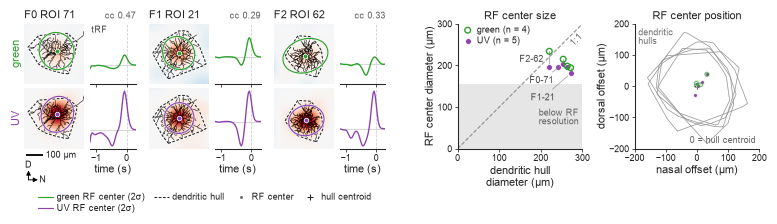

In [27]:
fig, lay, lim_k = make_figure(d_k, df_obs, K_SETTINGS)
print(f"{lay['W']:.2f} × {lay['H']:.2f} in; sRF {lay['s']:.2f} in (±{lim_k:.0f} µm), tRF width {lay['tw']:.2f} in, "
      f"statistics panels {lay['S']:.2f} in; K ends at {lay['k_right']:.2f} in (H / I: {FIG6_H_RIGHT}), L starts "
      f"at {lay['l_start']:.2f} in (J: {FIG6_J_LEFT})" + (f"\nNote: {lay['note']}" if lay["note"] else ""))
save(fig, "fig6KL_3cells", {"": None, "_K": lay["k_box"], "_L": lay["l_box"]})
plt.show()

# ROI 52 (F3)

F3 ROI 52: 1.24 × 1.46 in; sRF panels ±180 µm


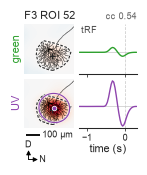

In [28]:
fig, lim = make_roi52_figure(row52)
w, h = fig.get_size_inches()
print(f"{row52.label}: {w:.2f} × {h:.2f} in; sRF panels ±{lim:.0f} µm")
save(fig, "fig6G_roi52_rf")
plt.show()

In [29]:
from watermark import watermark
print(watermark(packages="matplotlib,numpy,pandas,scipy,shapely,skeliner"))

matplotlib: 3.11.2
numpy     : 2.5.5
pandas    : 3.1.1
scipy     : 1.18.1
shapely   : 2.2.0
skeliner  : 0.3.1

